In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_excel("Online Retail.xlsx")

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [7]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
).round(2)

,Missing Values,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [10]:
df.duplicated().sum()

np.int64(5268)

In [11]:
df[df.duplicated()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


In [12]:
(df["Quantity"] < 0).sum()

np.int64(10624)

In [13]:
(df["UnitPrice"] <= 0).sum()

np.int64(2517)

In [14]:
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9288)

In [15]:
retail = df.copy()

print("Working copy created successfully!")
print("Original rows:", len(df))
print("Working rows:", len(retail))

Working copy created successfully!
Original rows: 541909
Working rows: 541909


In [16]:
duplicates_before = retail.duplicated().sum()

retail = retail.drop_duplicates().copy()

duplicates_after = retail.duplicated().sum()

print("Duplicates before cleaning:", duplicates_before)
print("Rows removed:", duplicates_before - duplicates_after)
print("Duplicates remaining:", duplicates_after)

Duplicates before cleaning: 5268
Rows removed: 5268
Duplicates remaining: 0


In [17]:
retail.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [18]:
missing_pct = (
    retail.isnull().sum() / len(retail) * 100
).round(2)

print(missing_pct.sort_values(ascending=False))

CustomerID     25.16
Description     0.27
StockCode       0.00
InvoiceNo       0.00
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
Country         0.00
dtype: float64


In [19]:
retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"],
    errors="coerce"
)

retail["Quantity"] = pd.to_numeric(
    retail["Quantity"],
    errors="coerce"
)

retail["UnitPrice"] = pd.to_numeric(
    retail["UnitPrice"],
    errors="coerce"
)

print(retail[["InvoiceDate", "Quantity", "UnitPrice"]].dtypes)

InvoiceDate    datetime64[us]
Quantity                int64
UnitPrice             float64
dtype: object


In [20]:
retail["Revenue"] = retail["Quantity"] * retail["UnitPrice"]

retail[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [21]:
sales = retail[
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0) &
    (~retail["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

print("All cleaned records:", len(retail))
print("Positive-price sales lines:", len(sales))
print("Sales revenue:", round(sales["Revenue"].sum(), 2))

All cleaned records: 536641
Positive-price sales lines: 524878
Sales revenue: 10642110.8


In [22]:
print("Remaining exact duplicates:", retail.duplicated().sum())
print("Missing invoice dates:", retail["InvoiceDate"].isnull().sum())
print("Missing quantities:", retail["Quantity"].isnull().sum())
print("Missing unit prices:", retail["UnitPrice"].isnull().sum())
print("Missing customer IDs:", retail["CustomerID"].isnull().sum())
print("Total cleaned records:", len(retail))

Remaining exact duplicates: 0
Missing invoice dates: 0
Missing quantities: 0
Missing unit prices: 0
Missing customer IDs: 135037
Total cleaned records: 536641


In [23]:
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")
monthly_sales = sales.groupby("YearMonth")["Revenue"].sum()
print(monthly_sales)

YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64


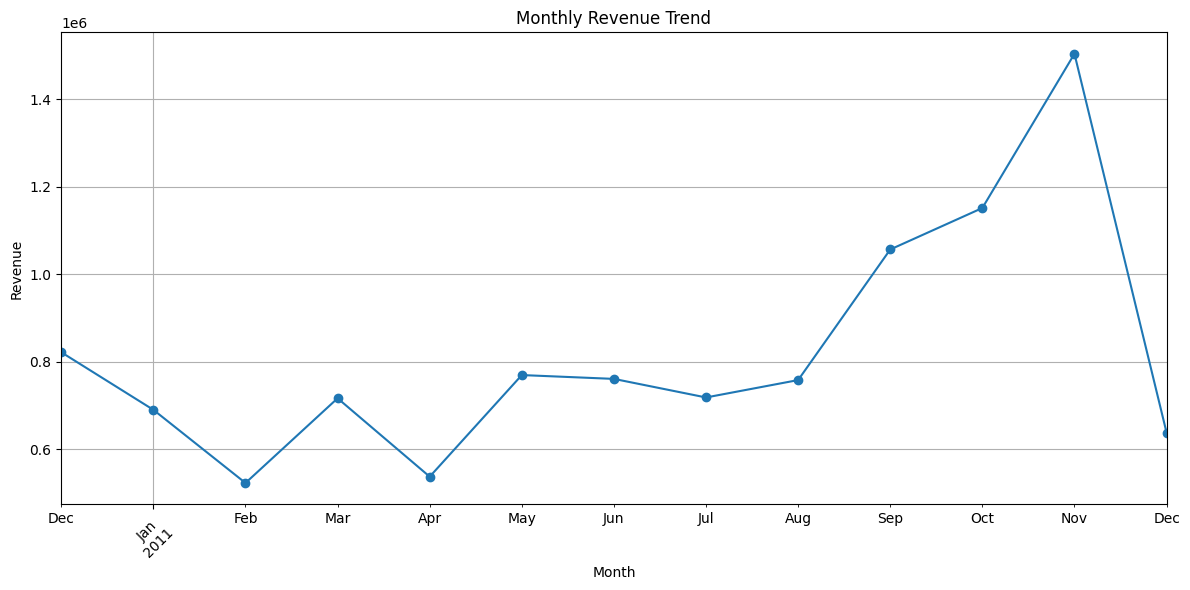

In [24]:
plt.figure(figsize=(12, 6))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
product_sales = sales.groupby("Description")["Revenue"].sum()
top_products = product_sales.sort_values(ascending=False).head(10)
print(top_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


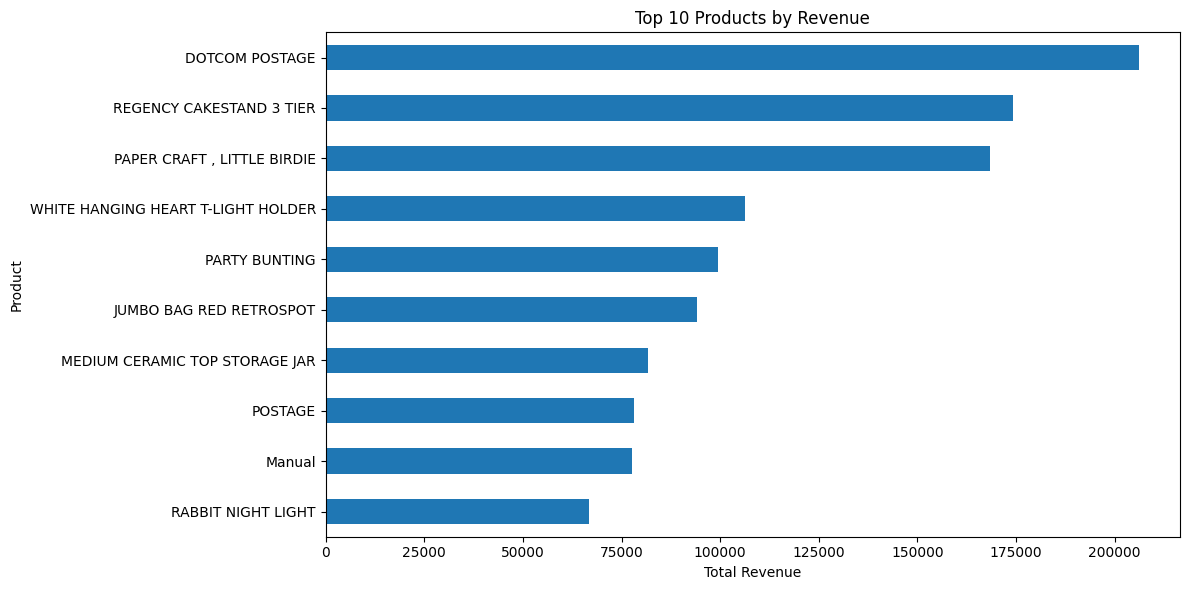

In [26]:
plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [27]:
product_quantity = sales.groupby("Description")["Quantity"].sum()
top_quantity_products = product_quantity.sort_values(
    ascending=False
).head(10)
print(top_quantity_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


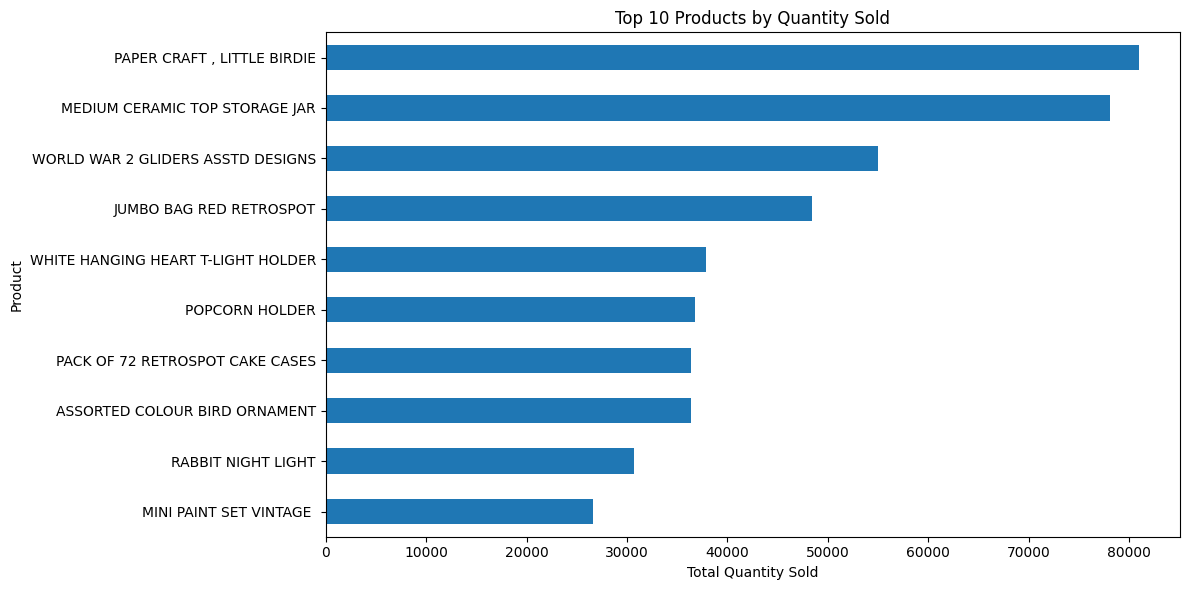

In [28]:
plt.figure(figsize=(12, 6))
top_quantity_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [29]:
customer_sales = sales.groupby("CustomerID")["Revenue"].sum()
top_customers = customer_sales.sort_values(
    ascending=False
).head(10)
print(top_customers)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


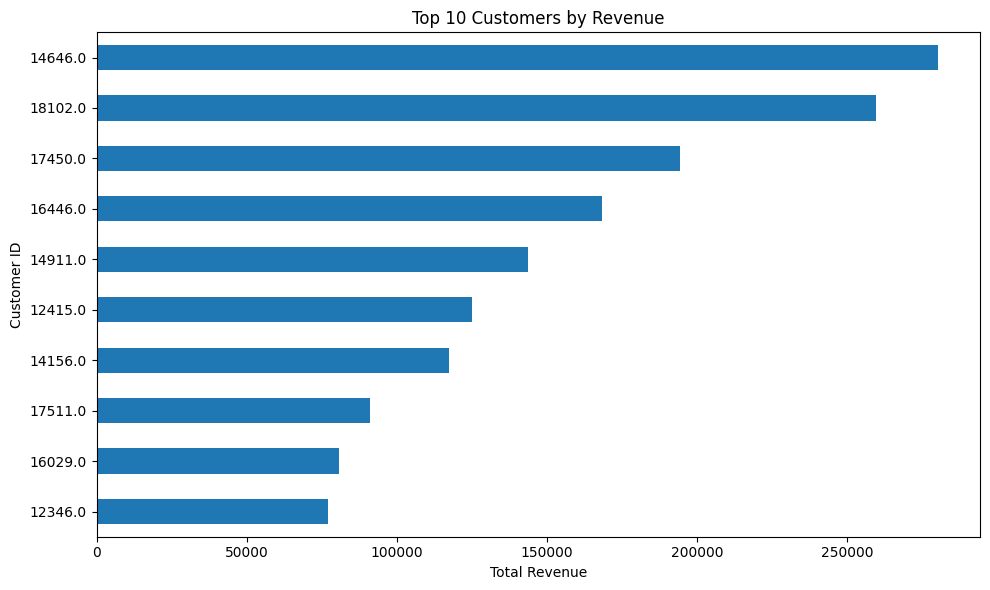

In [30]:
plt.figure(figsize=(10, 6))
top_customers.sort_values().plot(kind="barh")
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [31]:
country_sales = sales.groupby("Country")["Revenue"].sum()
top_countries = country_sales.sort_values(
    ascending=False
).head(10)
print(top_countries)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


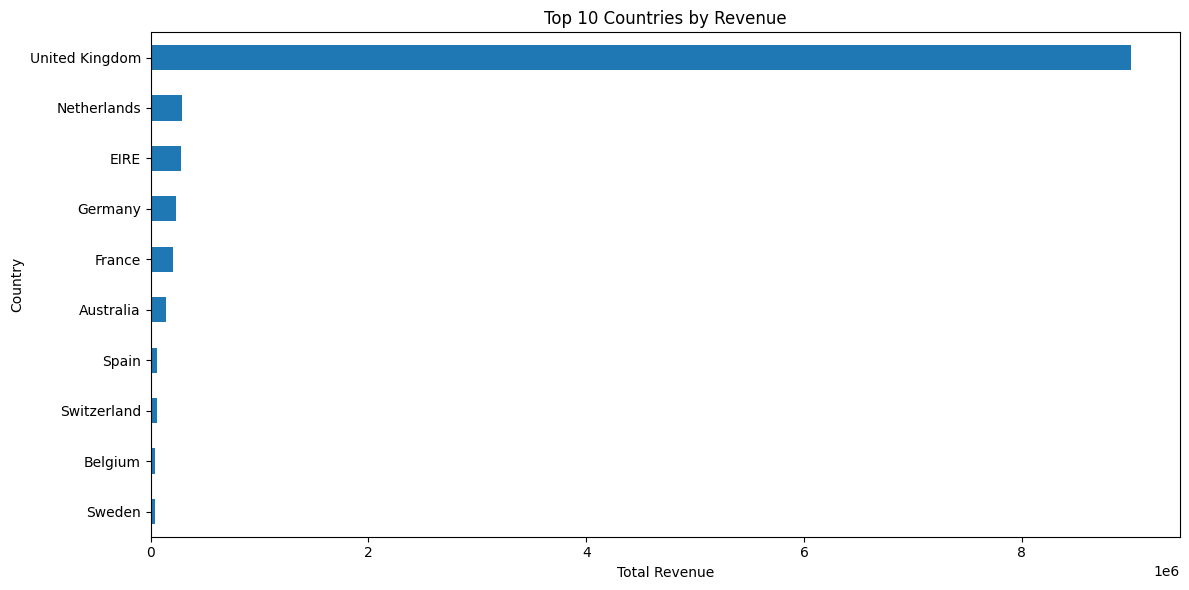

In [32]:
plt.figure(figsize=(12, 6))
top_countries.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [33]:
snapshot_date = sales["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Analysis reference date:", snapshot_date)

Analysis reference date: 2011-12-10 12:50:00


In [34]:
rfm = sales.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum"
})
rfm.columns = ["Recency", "Frequency", "Monetary"]
print(rfm.head(10))

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
12352.0          36          8   2506.04
12353.0         204          1     89.00
12354.0         232          1   1079.40
12355.0         214          1    459.40
12356.0          23          3   2811.43


In [35]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)
print(rfm.head(10))

            Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
CustomerID                                                                   
12346.0         326          1  77183.60        1        1        4       114
12347.0           2          7   4310.00        4        4        4       444
12348.0          75          4   1797.24        2        3        4       234
12349.0          19          1   1757.55        3        1        4       314
12350.0         310          1    334.40        1        1        2       112
12352.0          36          8   2506.04        3        4        4       344
12353.0         204          1     89.00        1        1        1       111
12354.0         232          1   1079.40        1        1        3       113
12355.0         214          1    459.40        1        1        2       112
12356.0          23          3   2811.43        3        3        4       334


In [36]:
def segment_customer(row):
    if row["RFM_Score"] == "444":
        return "High Value"
    elif row["F_Score"] == 4:
        return "Loyal Customers"
    elif row["R_Score"] == 1:
        return "At Risk"
    else:
        return "Others"
rfm["Segment"] = rfm.apply(segment_customer, axis=1)
print(rfm[["Recency", "Frequency", "Monetary",
           "RFM_Score", "Segment"]].head(10))

            Recency  Frequency  Monetary RFM_Score          Segment
CustomerID                                                         
12346.0         326          1  77183.60       114          At Risk
12347.0           2          7   4310.00       444       High Value
12348.0          75          4   1797.24       234           Others
12349.0          19          1   1757.55       314           Others
12350.0         310          1    334.40       112          At Risk
12352.0          36          8   2506.04       344  Loyal Customers
12353.0         204          1     89.00       111          At Risk
12354.0         232          1   1079.40       113          At Risk
12355.0         214          1    459.40       112          At Risk
12356.0          23          3   2811.43       334           Others


In [37]:
segment_counts = rfm["Segment"].value_counts()
print(segment_counts)

Segment
Others             2196
At Risk            1057
Loyal Customers     608
High Value          477
Name: count, dtype: int64


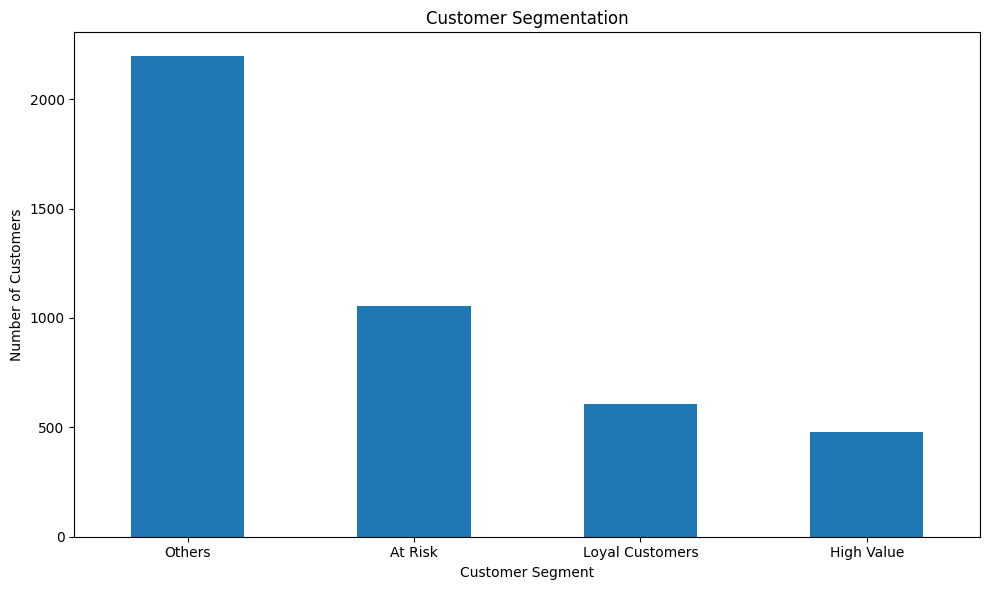

In [38]:
plt.figure(figsize=(10, 6))
segment_counts.plot(kind="bar")
plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

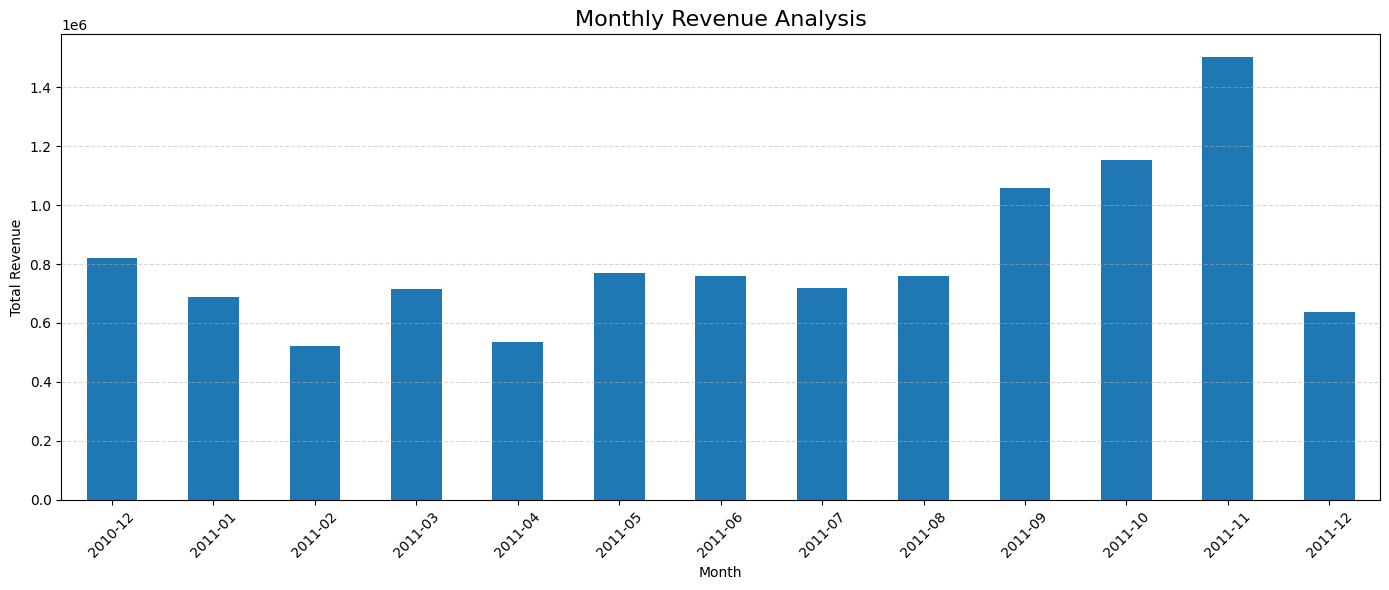

In [39]:
plt.figure(figsize=(14, 6))
monthly_sales.plot(kind="bar")
plt.title("Monthly Revenue Analysis", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [40]:
highest_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()
print("Highest Revenue Month:", highest_month)
print("Highest Revenue:", round(monthly_sales.max(), 2))
print("\nLowest Revenue Month:", lowest_month)
print("Lowest Revenue:", round(monthly_sales.min(), 2))

Highest Revenue Month: 2011-11
Highest Revenue: 1503866.78

Lowest Revenue Month: 2011-02
Lowest Revenue: 522545.56


In [41]:
total_orders = sales["InvoiceNo"].nunique()
total_revenue = sales["Revenue"].sum()
average_order_value = total_revenue / total_orders
print("Total Orders:", total_orders)
print("Total Revenue:", round(total_revenue, 2))
print("Average Order Value:", round(average_order_value, 2))

Total Orders: 19960
Total Revenue: 10642110.8
Average Order Value: 533.17


In [42]:
metrics = pd.Series({
    "Total Orders": total_orders,
    "Total Revenue": total_revenue,
    "Average Order Value": average_order_value
})
print(metrics)

Total Orders           1.996000e+04
Total Revenue          1.064211e+07
Average Order Value    5.331719e+02
dtype: float64


In [43]:
missing_values = sales.isnull().sum()
print("Missing values in each column:")
print(missing_values)

Missing values in each column:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
YearMonth           0
dtype: int64


In [44]:
duplicate_count = sales.duplicated().sum()
print("Duplicate records remaining:", duplicate_count)

Duplicate records remaining: 0


In [45]:
negative_quantity = (sales["Quantity"] < 0).sum()
negative_price = (sales["UnitPrice"] < 0).sum()
print("Negative quantity records:", negative_quantity)
print("Negative price records:", negative_price)

Negative quantity records: 0
Negative price records: 0


In [46]:
valid_customer_rows = sales["CustomerID"].notna().sum()
missing_customer_rows = sales["CustomerID"].isna().sum()
missing_percentage = (
    missing_customer_rows / len(sales)
) * 100
print("Total sales records:", len(sales))
print("Records with CustomerID:", valid_customer_rows)
print("Records without CustomerID:", missing_customer_rows)
print("Missing CustomerID percentage:", round(missing_percentage, 2), "%")

Total sales records: 524878
Records with CustomerID: 392692
Records without CustomerID: 132186
Missing CustomerID percentage: 25.18 %


In [47]:
customer_sales_data = sales.dropna(subset=["CustomerID"]).copy()
print("Customer analysis records:", len(customer_sales_data))
print(
    "Unique identified customers:",
    customer_sales_data["CustomerID"].nunique()
)

Customer analysis records: 392692
Unique identified customers: 4338


In [48]:
segment_revenue = rfm.groupby("Segment")["Monetary"].sum()
segment_revenue = segment_revenue.sort_values(ascending=False)
print("Revenue by Customer Segment:")
print(segment_revenue)

Revenue by Customer Segment:
Segment
High Value         4382901.950
Others             2002588.033
Loyal Customers    1858610.830
At Risk             643108.081
Name: Monetary, dtype: float64


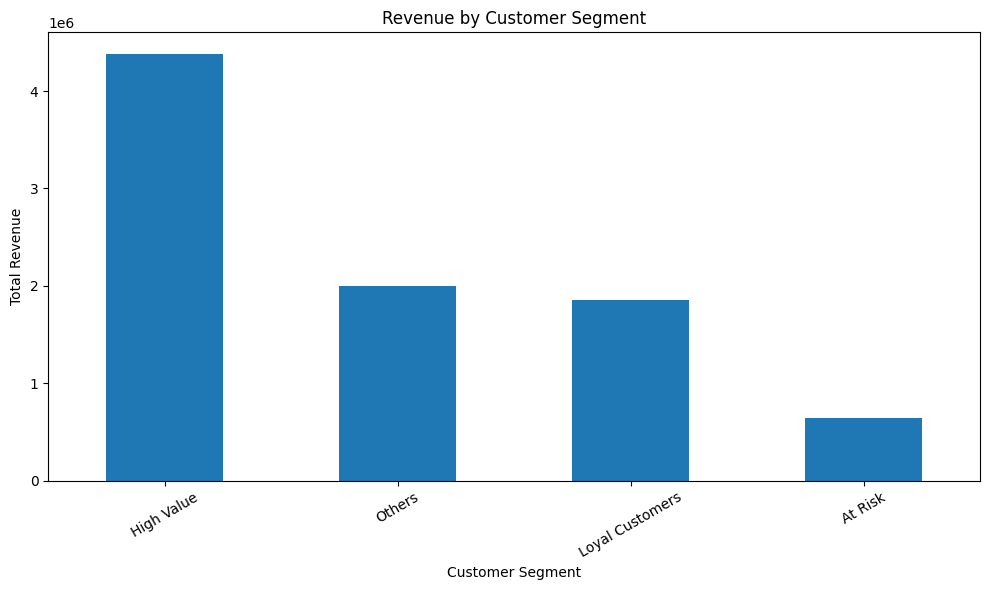

In [49]:
plt.figure(figsize=(10, 6))
segment_revenue.plot(kind="bar")
plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [50]:
total_segment_revenue = segment_revenue.sum()
segment_percentage = (
    segment_revenue / total_segment_revenue
) * 100
print("Revenue Contribution by Customer Segment:")
print(segment_percentage.round(2))

Revenue Contribution by Customer Segment:
Segment
High Value         49.32
Others             22.53
Loyal Customers    20.91
At Risk             7.24
Name: Monetary, dtype: float64


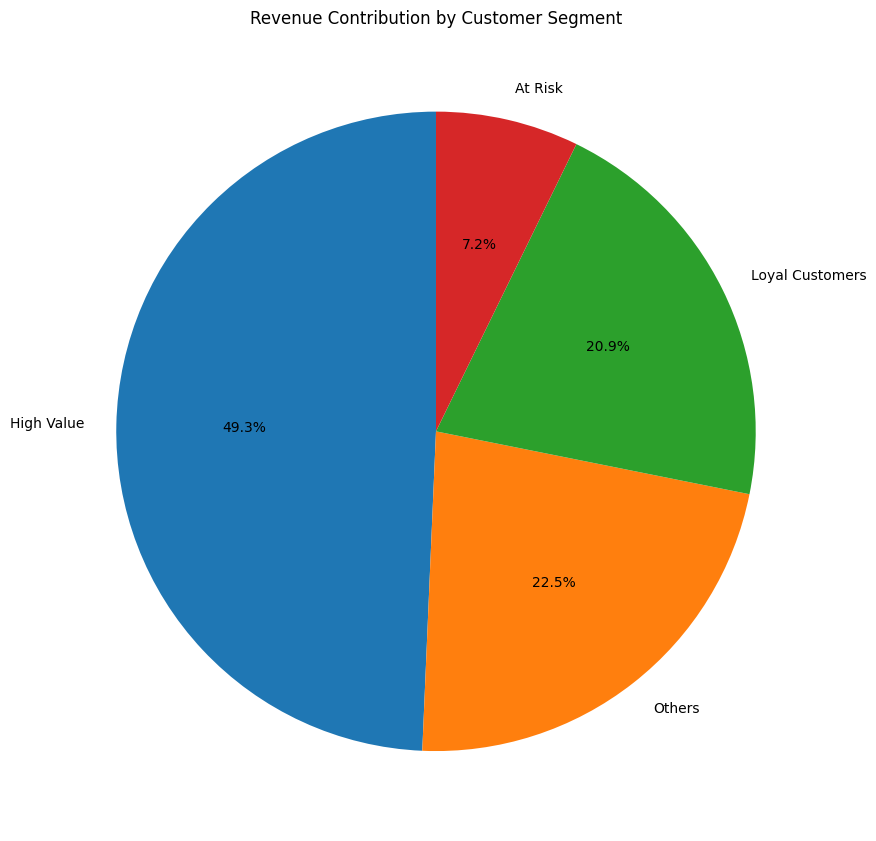

In [51]:
plt.figure(figsize=(9, 9))
segment_percentage.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Revenue Contribution by Customer Segment")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [52]:
print("Sample invoice numbers:")
print(sales["InvoiceNo"].astype(str).head(10))
cancelled_invoices = sales["InvoiceNo"].astype(str).str.startswith("C").sum()
print("\nInvoices beginning with C:", cancelled_invoices)

Sample invoice numbers:
0    536365
1    536365
2    536365
3    536365
4    536365
5    536365
6    536365
7    536366
8    536366
9    536367
Name: InvoiceNo, dtype: str

Invoices beginning with C: 0


In [53]:
invoice_numbers = sales["InvoiceNo"].astype(str)
cancelled_invoices = invoice_numbers.str.startswith("C").sum()
print("Invoices beginning with C:", cancelled_invoices)

Invoices beginning with C: 0


In [54]:
print(sales["Revenue"].describe())

count    524878.000000
mean         20.275399
std         271.693566
min           0.001000
25%           3.900000
50%           9.920000
75%          17.700000
max      168469.600000
Name: Revenue, dtype: float64


In [55]:
sales["DayOfWeek"] = sales["InvoiceDate"].dt.day_name()
weekday_sales = sales.groupby("DayOfWeek")["Revenue"].sum()
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]
weekday_sales = weekday_sales.reindex(day_order)
print("Revenue by Day of the Week:")
print(weekday_sales)

Revenue by Day of the Week:
DayOfWeek
Monday       1775782.071
Tuesday      2175700.511
Wednesday    1847074.380
Thursday     2199292.570
Friday       1837470.491
Saturday             NaN
Sunday        806790.781
Name: Revenue, dtype: float64


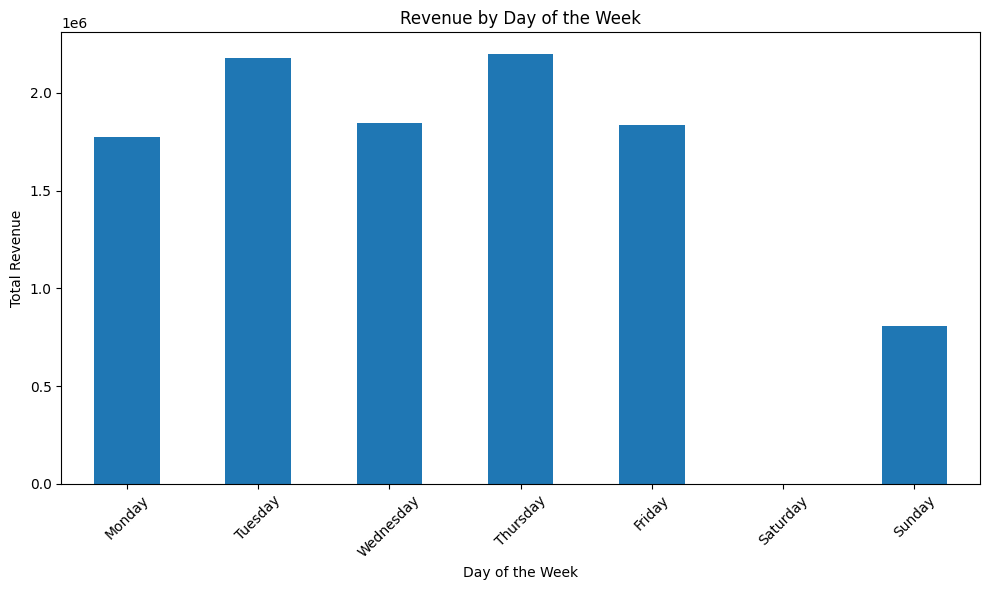

In [56]:
plt.figure(figsize=(10, 6))
weekday_sales.plot(kind="bar")
plt.title("Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
best_day = weekday_sales.idxmax()
best_day_revenue = weekday_sales.max()
print("Highest Revenue Day:", best_day)
print("Revenue:", round(best_day_revenue, 2))

Highest Revenue Day: Thursday
Revenue: 2199292.57


In [58]:
monthly_orders = sales.groupby("YearMonth")["InvoiceNo"].nunique()
print(monthly_orders)

YearMonth
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1475
2011-08    1361
2011-09    1837
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: InvoiceNo, dtype: int64


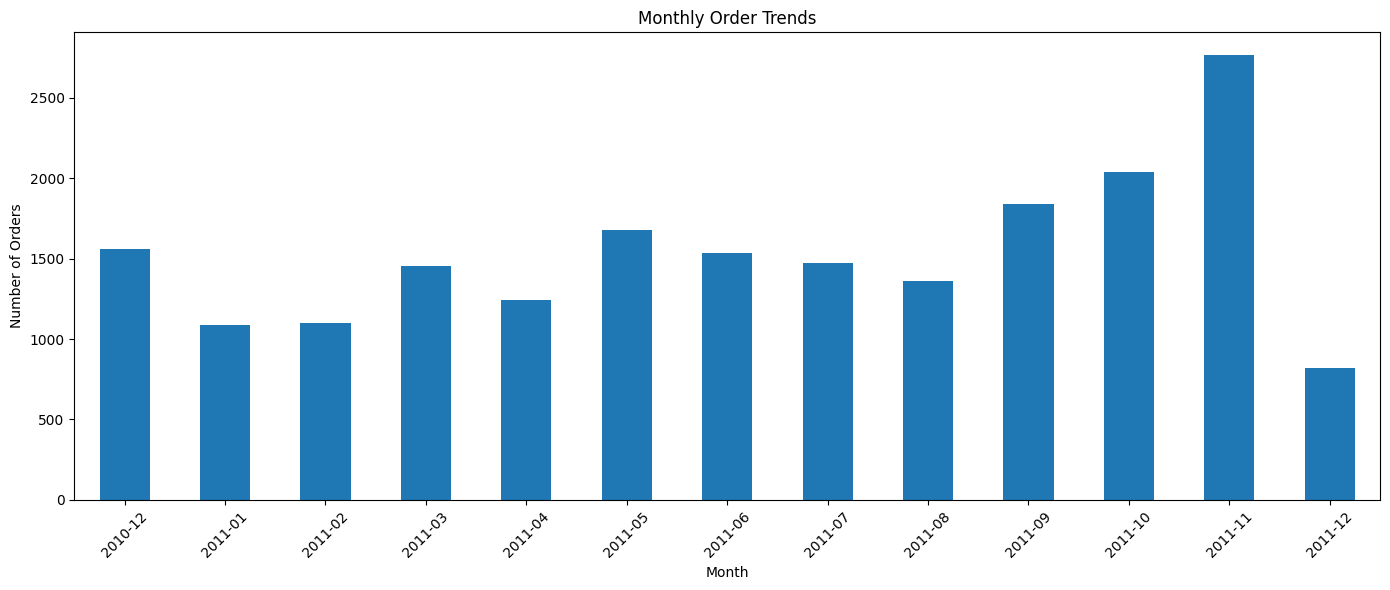

In [59]:
plt.figure(figsize=(14, 6))
monthly_orders.plot(kind="bar")
plt.title("Monthly Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [60]:
print("Highest Order Month:", monthly_orders.idxmax())
print("Number of Orders:", monthly_orders.max())

Highest Order Month: 2011-11
Number of Orders: 2769


In [61]:
monthly_aov = (
    sales.groupby("YearMonth")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique")
    )
)
monthly_aov["Average_Order_Value"] = (
    monthly_aov["Total_Revenue"] /
    monthly_aov["Total_Orders"]
)
print(monthly_aov.head(10))

           Total_Revenue  Total_Orders  Average_Order_Value
YearMonth                                                  
2010-12       821452.730          1559           526.910026
2011-01       689811.610          1086           635.185645
2011-02       522545.560          1100           475.041418
2011-03       716215.260          1454           492.582710
2011-04       536968.491          1246           430.953845
2011-05       769296.610          1681           457.642243
2011-06       760547.010          1533           496.116771
2011-07       718076.121          1475           486.831268
2011-08       757841.380          1361           556.826877
2011-09      1056435.192          1837           575.087203


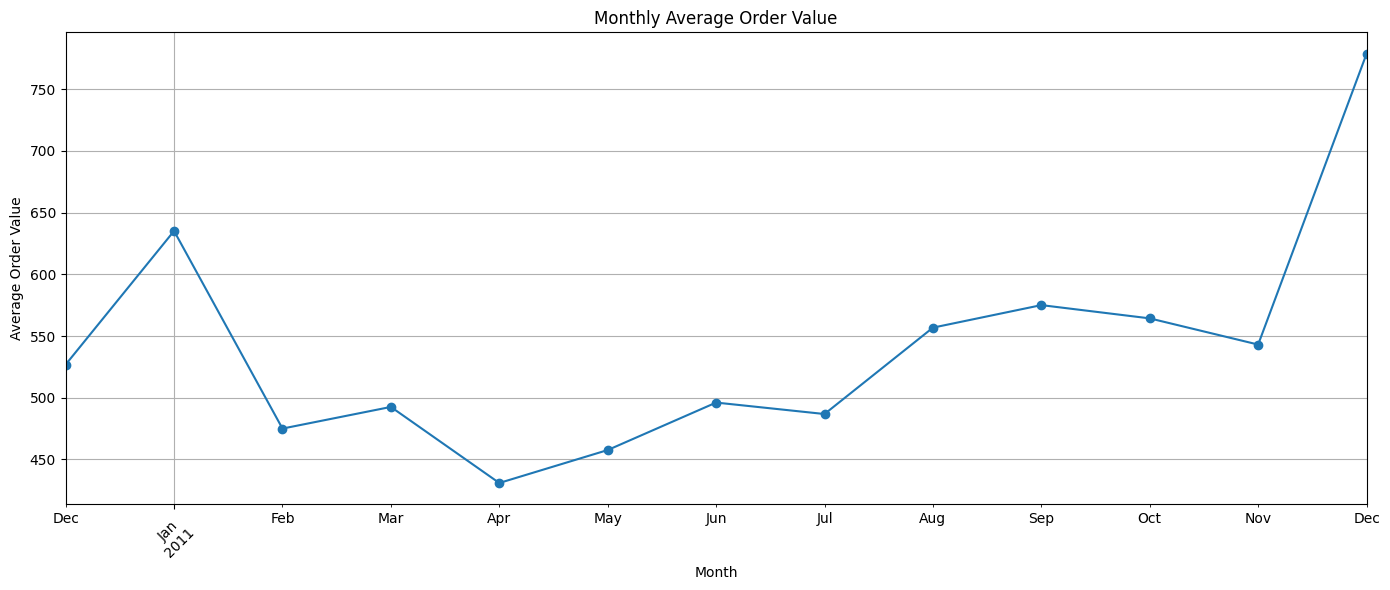

In [62]:
plt.figure(figsize=(14, 6))
monthly_aov["Average_Order_Value"].plot(
    kind="line",
    marker="o"
)
plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [63]:
print(
    "Highest AOV Month:",
    monthly_aov["Average_Order_Value"].idxmax()
)
print(
    "Highest AOV:",
    round(monthly_aov["Average_Order_Value"].max(), 2)
)
print(
    "Lowest AOV Month:",
    monthly_aov["Average_Order_Value"].idxmin()
)
print(
    "Lowest AOV:",
    round(monthly_aov["Average_Order_Value"].min(), 2)
)

Highest AOV Month: 2011-12
Highest AOV: 778.74
Lowest AOV Month: 2011-04
Lowest AOV: 430.95


In [64]:
top_product_names = sales["Description"].value_counts().head(15)
print(top_product_names)

Description
WHITE HANGING HEART T-LIGHT HOLDER    2311
JUMBO BAG RED RETROSPOT               2109
REGENCY CAKESTAND 3 TIER              2007
PARTY BUNTING                         1699
LUNCH BAG RED RETROSPOT               1581
ASSORTED COLOUR BIRD ORNAMENT         1476
SET OF 3 CAKE TINS PANTRY DESIGN      1392
PACK OF 72 RETROSPOT CAKE CASES       1352
LUNCH BAG  BLACK SKULL.               1301
NATURAL SLATE HEART CHALKBOARD        1255
JUMBO BAG PINK POLKADOT               1232
HEART OF WICKER SMALL                 1219
JUMBO STORAGE BAG SUKI                1194
PAPER CHAIN KIT 50'S CHRISTMAS        1184
JUMBO SHOPPER VINTAGE RED PAISLEY     1180
Name: count, dtype: int64


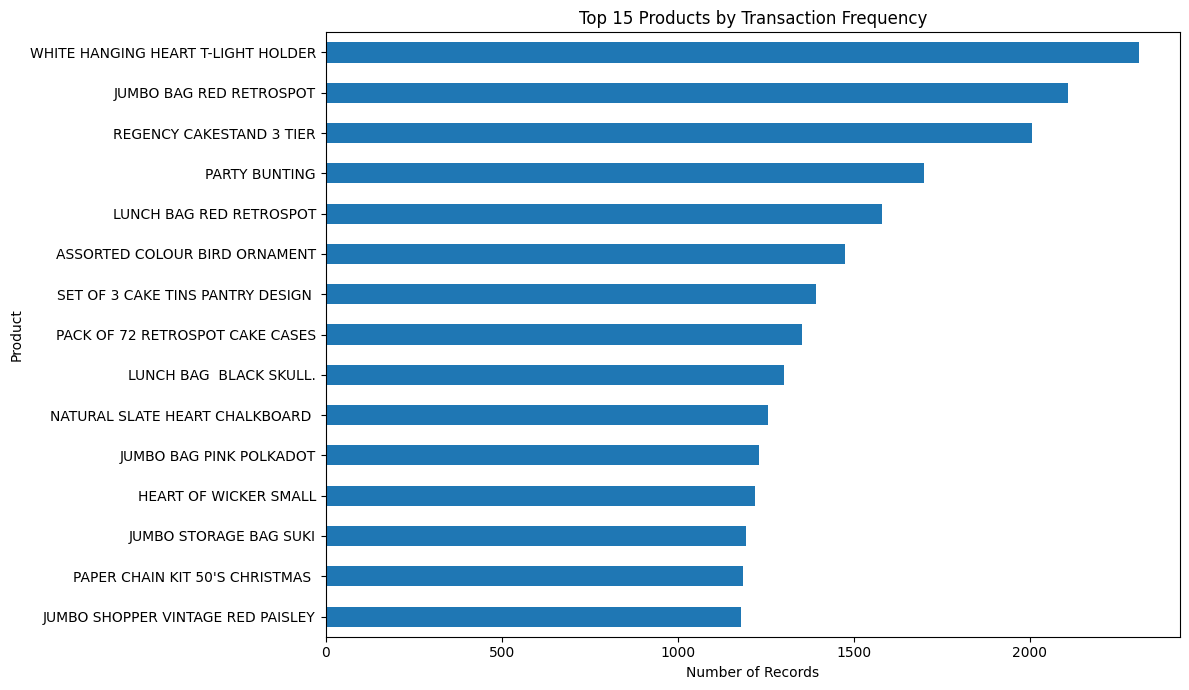

In [65]:
plt.figure(figsize=(12, 7))
top_product_names.sort_values().plot(kind="barh")
plt.title("Top 15 Products by Transaction Frequency")
plt.xlabel("Number of Records")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [66]:
product_summary = sales.groupby("Description").agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Revenue", "sum")
)
product_summary = product_summary.sort_values(
    "Total_Revenue", ascending=False
).head(10)
print(product_summary)

                                    Total_Quantity  Total_Revenue
Description                                                      
DOTCOM POSTAGE                                 706      206248.77
REGENCY CAKESTAND 3 TIER                     13851      174156.54
PAPER CRAFT , LITTLE BIRDIE                  80995      168469.60
WHITE HANGING HEART T-LIGHT HOLDER           37872      106236.72
PARTY BUNTING                                18283       99445.23
JUMBO BAG RED RETROSPOT                      48371       94159.81
MEDIUM CERAMIC TOP STORAGE JAR               78033       81700.92
POSTAGE                                       3150       78101.88
Manual                                        6985       77752.82
RABBIT NIGHT LIGHT                           30739       66870.03


In [67]:
correlation = sales[
    ["Quantity", "UnitPrice", "Revenue"]
].corr()
print(correlation)

           Quantity  UnitPrice   Revenue
Quantity   1.000000  -0.003788  0.907402
UnitPrice -0.003788   1.000000  0.137381
Revenue    0.907402   0.137381  1.000000


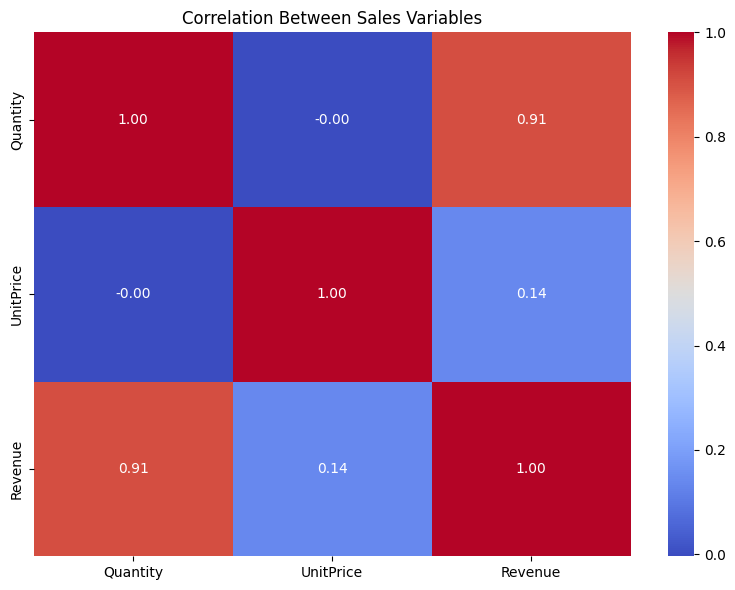

In [68]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Sales Variables")
plt.tight_layout()
plt.show()

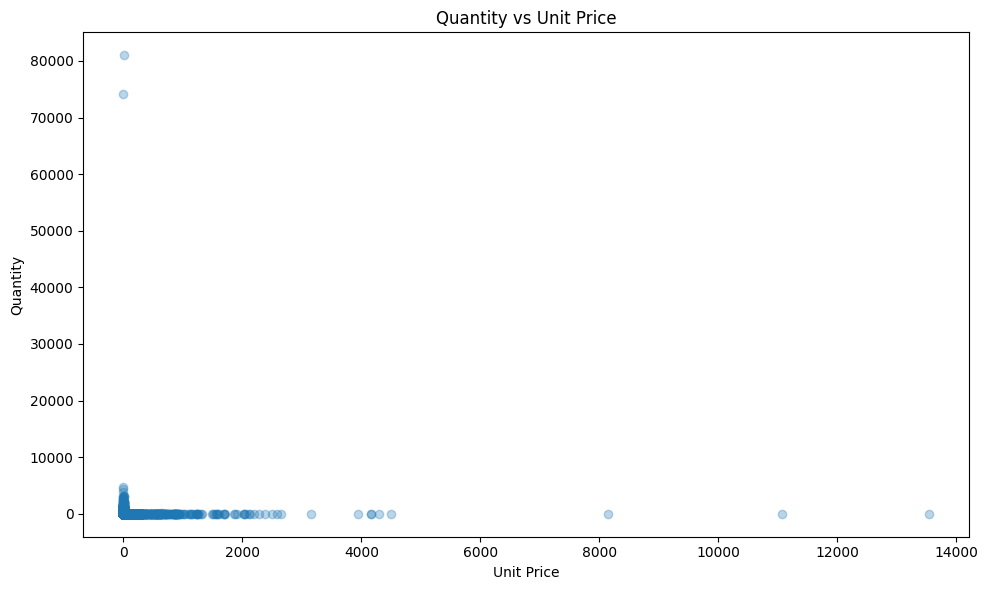

In [69]:
plt.figure(figsize=(10, 6))
plt.scatter(
    sales["UnitPrice"],
    sales["Quantity"],
    alpha=0.3
)
plt.title("Quantity vs Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

In [70]:
customer_orders = customer_sales_data.groupby("CustomerID")["InvoiceNo"].nunique()
top_frequent_customers = customer_orders.sort_values(
    ascending=False
).head(10)
print(top_frequent_customers)

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64


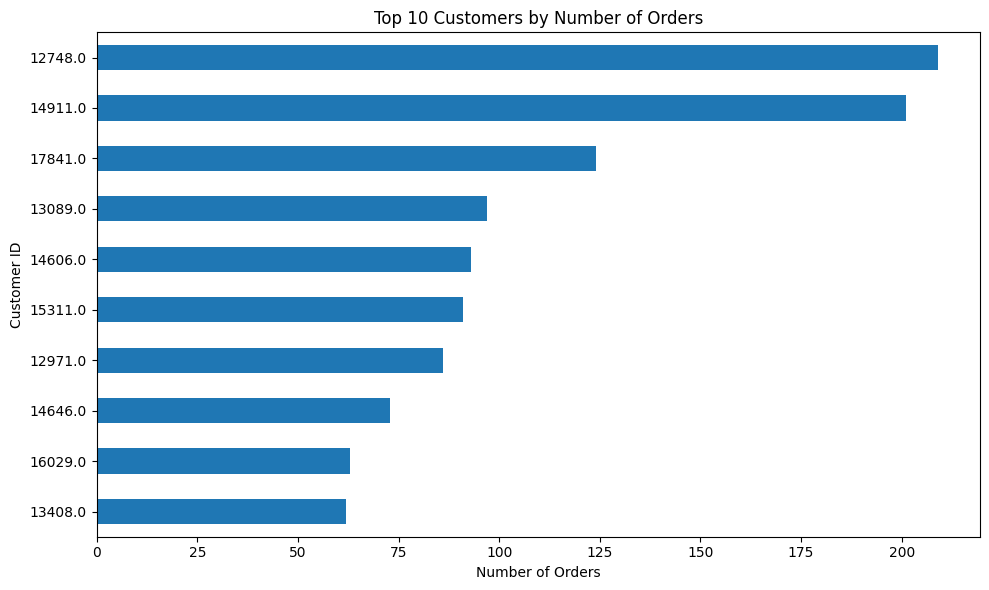

In [71]:
plt.figure(figsize=(10, 6))
top_frequent_customers.sort_values().plot(kind="barh")
plt.title("Top 10 Customers by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [72]:
print(
    "Average Orders per Customer:",
    round(customer_orders.mean(), 2)
)
print(
    "Maximum Orders by One Customer:",
    customer_orders.max()
)

Average Orders per Customer: 4.27
Maximum Orders by One Customer: 209


In [73]:
print("RETAIL ANALYTICS — KEY FINDINGS")
print("-" * 40)
print("Total Revenue:", round(sales["Revenue"].sum(), 2))
print("Total Orders:", sales["InvoiceNo"].nunique())
print("Average Order Value:", round(
    sales["Revenue"].sum() / sales["InvoiceNo"].nunique(), 2
))
print("\nHighest Revenue Month:", monthly_sales.idxmax())
print("Highest Revenue:", round(monthly_sales.max(), 2))
print("\nTop Product by Revenue:", product_sales.idxmax())
print("Top Product Revenue:", round(product_sales.max(), 2))
print("\nTop Country by Revenue:", country_sales.idxmax())
print("Top Country Revenue:", round(country_sales.max(), 2))
print("\nTop Customer Segment by Revenue:", segment_revenue.idxmax())
print("Segment Revenue:", round(segment_revenue.max(), 2))

RETAIL ANALYTICS — KEY FINDINGS
----------------------------------------
Total Revenue: 10642110.8
Total Orders: 19960
Average Order Value: 533.17

Highest Revenue Month: 2011-11
Highest Revenue: 1503866.78

Top Product by Revenue: DOTCOM POSTAGE
Top Product Revenue: 206248.77

Top Country by Revenue: United Kingdom
Top Country Revenue: 9001744.09

Top Customer Segment by Revenue: High Value
Segment Revenue: 4382901.95


In [74]:
sales.to_csv("retail_sales_cleaned.csv", index=False)

In [75]:
rfm.to_csv("customer_rfm_analysis.csv")

# Retail Sales and Customer Analytics

## Project Overview
This project analyzes retail transaction data using Python to identify sales trends, top-performing products, key markets, and customer purchasing patterns.

## Objectives
- Analyze monthly revenue trends.
- Identify top-selling products.
- Analyze customer purchasing behavior.
- Compare revenue across countries.
- Perform RFM customer segmentation.
- Generate actionable business insights.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Key Findings
- Total recorded revenue: 10,642,110.80
- Total unique invoices: 19,960
- Average recorded revenue per invoice: 533.17
- Highest revenue month: November 2011
- Highest revenue country: United Kingdom
- Highest revenue product by recorded revenue: DOTCOM POSTAGE
- Largest revenue-contributing RFM segment: High Value

## Customer Segmentation
Customers were classified into four preliminary groups:
- High Value
- Loyal Customers
- At Risk
- Others

## Conclusion
The analysis provides insights into revenue trends, product performance, and customer behavior that can help businesses make data-informed decisions.

## Limitations
Some transactions have missing CustomerIDs. Customer-level findings therefore cover identified customers only. Revenue figures and customer segments should be interpreted in light of the dataset's cleaning and filtering rules.

In [78]:
sales.to_csv("retail_sales_cleaned.csv", index=False)
rfm.to_csv("customer_rfm_analysis.csv")